# HICO-DET: EDA đơn giản

**Mục tiêu:** hiểu bộ dữ liệu trước khi training, theo 4 bước:
1. Dữ liệu gốc trông như thế nào (bao nhiêu ảnh, 600 loại tương tác, xem ảnh)
2. Map sang **6 nhãn đích**: `hold`, `ride`, `eat/drink`, `take_on_phone`, `work_on_computer`, `unknown`
3. Soi những chỗ **map đáng nghi**, có ảnh để tự kiểm tra
4. Lớp `hold` quá rộng: dẫn chứng bằng số liệu và đề xuất giới hạn

**Đặc điểm bộ này:**
- Nhãn là các **cặp tương tác HOI** (Human-Object Interaction) dạng **(vật, động từ)**, ví dụ `('cell_phone', 'talk_on')`, `('horse', 'ride')`.
- Có **600 loại cặp** = 80 loại vật × 117 động từ (chỉ những cặp có nghĩa).
- Mỗi cặp có **2 bbox**: bbox người (`bbox_human`) và bbox vật (`bbox_object`).
- 1 ảnh thường có **nhiều cặp** (nhiều người, hoặc 1 người làm nhiều việc).

## Phần 0: Tải dữ liệu

**Lấy từ đâu?** Hugging Face, dataset `zhimeng/hico_det` (38.118 ảnh train + 9.658 ảnh test, ~8GB).

**Cách tải:** dùng chế độ **streaming**: đọc từng ảnh qua mạng, **không tải hết về máy**. Ta chỉ lấy `N_SAMPLES` ảnh đầu tiên (mặc định 3000) để làm EDA. Muốn nhiều hơn thì tăng số này.

**Chuẩn bị `HF_TOKEN`** (nên có để tải nhanh và ổn định, không bắt buộc):
1. Vào https://huggingface.co/settings/tokens, bấm **Create new token**, chọn loại **Read**, rồi copy token
2. Trên Colab: bấm biểu tượng 🔑 (**Secrets**) ở thanh bên trái → **Add new secret** → Name: `HF_TOKEN`, Value: dán token → bật **Notebook access**
3. Chạy trên máy: đặt biến môi trường `export HF_TOKEN=...` trước khi mở Jupyter

⏱️ Trên Colab, 3000 ảnh mất khoảng 2–5 phút.

In [ ]:
!pip install -q datasets huggingface_hub

### 🧰 Công cụ dùng chung
Cell dưới đây định nghĩa **6 nhãn đích**, **bảng màu** và vài hàm vẽ. Cả 4 notebook dùng chung cell này, **chỉ cần chạy, không cần sửa**.

- `bang_dem(series)`: đếm số lượng và tỷ lệ % của từng nhãn
- `ve_cot(series, title)`: vẽ biểu đồ cột số lượng
- `show_grid(items, title)`: hiện một lưới ảnh, có thể kèm **bbox** (bounding box: khung chữ nhật đánh dấu vị trí người/vật trong ảnh)

In [ ]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 100)
random.seed(42); np.random.seed(42)

# 6 nhãn đích của bài toán
TARGET_CLASSES = ['hold', 'ride', 'eat/drink', 'take_on_phone', 'work_on_computer', 'unknown']
# Thứ tự ưu tiên khi 1 người có nhiều nhãn (priority rule): nhãn cụ thể thắng nhãn chung chung
PRIORITY = ['take_on_phone', 'work_on_computer', 'eat/drink', 'ride', 'hold', 'unknown']
CLASS_COLORS = {'hold': '#00C853', 'ride': '#2979FF', 'eat/drink': '#FF9100',
                'take_on_phone': '#D500F9', 'work_on_computer': '#00B8D4', 'unknown': '#9E9E9E'}


def bang_dem(series, ten_cot='nhãn'):
    """Bảng đếm: mỗi nhãn có bao nhiêu mẫu, chiếm bao nhiêu %."""
    vc = series.value_counts()
    return pd.DataFrame({ten_cot: vc.index, 'số lượng': vc.values,
                         'tỷ lệ %': (vc.values / vc.sum() * 100).round(1)})


def ve_cot(series, title, theo_6_lop=False, xoay=60):
    """Biểu đồ cột số lượng mỗi nhãn. theo_6_lop=True: giữ đúng thứ tự + màu của 6 lớp."""
    if theo_6_lop:
        vc = series.value_counts().reindex(TARGET_CLASSES, fill_value=0)
        colors = [CLASS_COLORS[c] for c in vc.index]
    else:
        vc = series.value_counts()
        colors = '#5C6BC0'
    fig, ax = plt.subplots(figsize=(max(6, 0.35 * len(vc) + 3), 4))
    ax.bar(vc.index.astype(str), vc.values, color=colors)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)
    ax.set_title(title, weight='bold'); ax.set_ylabel('số lượng')
    ax.tick_params(axis='x', rotation=xoay)
    plt.tight_layout(); plt.show()


def show_grid(items, title='', ncols=6, size=2.6):
    """Hiện lưới ảnh.
    items: list các dict {'img': PIL.Image hoặc đường dẫn, 'title': chữ dưới ảnh,
                          'boxes': [(x1, y1, x2, y2, màu, chữ), ...]}  (boxes không bắt buộc)"""
    if len(items) == 0:
        print('⚠️ Không có ảnh nào để hiển thị'); return
    ncols = min(ncols, len(items))
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.8), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, it in zip(axes.ravel(), items):
        img = it.get('img')
        if isinstance(img, str):
            img = Image.open(img)
        if img is None:
            ax.set_title('(không tải được ảnh)', fontsize=8); continue
        ax.imshow(img)
        for (x1, y1, x2, y2, color, label) in it.get('boxes', []):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
            if label:
                ax.text(x1, y1, label, color='white', fontsize=7, va='bottom',
                        bbox=dict(facecolor=color, pad=1, edgecolor='none'))
        ax.set_title(it.get('title', ''), fontsize=8)
    fig.suptitle(title, fontsize=12, weight='bold')
    plt.tight_layout(); plt.show()

print('✅ Đã nạp công cụ dùng chung')

✅ Đã nạp công cụ dùng chung


In [ ]:
import io, ast
from datasets import load_dataset
from huggingface_hub import hf_hub_download

try:                                            # Colab: đọc token từ Secrets
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN') or ''
except Exception:
    pass
print('HF_TOKEN:', '✅ đã có' if os.environ.get('HF_TOKEN') else '⚠️ chưa có (vẫn chạy được, có thể chậm hơn)')

N_SAMPLES = 3000   # 👈 số ảnh lấy về để làm EDA
ds = load_dataset('zhimeng/hico_det', split='train', streaming=True)

HF_TOKEN: ✅ đã có


README.md:   0%|          | 0.00/4.32k [00:00<?, ?B/s]

**Đọc N ảnh.** Với mỗi ảnh ta lưu:
- danh sách **cặp (vật, động từ)** và bbox người/vật của từng cặp
- một **ảnh thu nhỏ** (tối đa 320 pixel) để xem sau, không phải tải lại

⚠️ Bbox của HICO-DET có dạng `[xmin, xmax, ymin, ymax]` (khác thứ tự thông thường `[x1, y1, x2, y2]`), nên phải đổi lại khi vẽ.

In [ ]:
THUMB = 320
thumbs, rows = {}, []

for idx, s in enumerate(ds.take(N_SAMPLES)):      # take(N): chỉ lấy N ảnh đầu tiên
    captions = ast.literal_eval(s['positive_captions'])      # [(vật, động từ), ...]
    hoi_ids = ast.literal_eval(s['positive_objects'])         # id loại HOI của từng caption
    pairs = []
    for o in ast.literal_eval(s['objects']):
        if o['id'] - 1 not in hoi_ids:                        # o['id'] đánh số từ 1, hoi_ids từ 0
            continue
        obj, verb = captions[hoi_ids.index(o['id'] - 1)]
        hb, ob = o['bbox_human'], o['bbox_object']
        if len(hb) != 4:                                      # một số cặp thiếu bbox người → bỏ qua
            continue
        pairs.append({'object': obj, 'verb': verb,
                      'hbox': (hb[0], hb[2], hb[1], hb[3]),    # đổi [xmin,xmax,ymin,ymax] → (x1,y1,x2,y2)
                      'obox': (ob[0], ob[2], ob[1], ob[3]) if len(ob) == 4 else None})
    img = s['image'].convert('RGB')
    w, h = img.size
    scale = min(1.0, THUMB / max(w, h))
    img.thumbnail((THUMB, THUMB))
    buf = io.BytesIO(); img.save(buf, 'JPEG', quality=85); thumbs[idx] = (buf.getvalue(), scale)
    rows.append({'idx': idx, 'width': w, 'height': h, 'captions': captions, 'pairs': pairs})
    if (idx + 1) % 500 == 0:
        print(f'  đã đọc {idx + 1} ảnh...')

df = pd.DataFrame(rows)
print(f'✅ Đã tải xong: {len(df)} ảnh')
df.head()

  đã đọc 500 ảnh...
  đã đọc 1000 ảnh...
  đã đọc 1500 ảnh...
  đã đọc 2000 ảnh...
  đã đọc 2500 ảnh...
  đã đọc 3000 ảnh...
✅ Đã tải xong: 3000 ảnh


,idx,width,height,captions,pairs
0,0,640,480,"[(motorcycle, race), (motorcycle, ride), (moto...","[{'object': 'motorcycle', 'verb': 'race', 'hbo..."
1,1,640,480,"[(banana, no_interaction)]","[{'object': 'banana', 'verb': 'no_interaction'..."
2,2,599,640,"[(bus, no_interaction)]","[{'object': 'bus', 'verb': 'no_interaction', '..."
3,3,640,427,"[(bottle, drink_with), (bottle, hold)]","[{'object': 'bottle', 'verb': 'drink_with', 'h..."
4,4,640,425,"[(bed, sit_on)]","[{'object': 'bed', 'verb': 'sit_on', 'hbox': (..."


In [ ]:
def anh_nho(idx):
    return Image.open(io.BytesIO(thumbs[idx][0]))

def item_cap(idx, pair, title, color='#00C853'):
    """1 ô ảnh cho show_grid: ảnh thu nhỏ + bbox người (màu lớp) + bbox vật (cam)."""
    s = thumbs[idx][1]
    boxes = []
    if pair is not None:
        boxes.append((*[v * s for v in pair['hbox']], color, 'người'))
        if pair['obox'] is not None:
            boxes.append((*[v * s for v in pair['obox']], '#FF9100', pair['object']))
    return {'img': anh_nho(idx), 'title': title, 'boxes': boxes}

## Phần 1: Dữ liệu gốc trông như thế nào?

### 1.1 Danh mục 600 loại tương tác
File `list_action.csv` liệt kê 600 cặp (vật, động từ) của HICO-DET.

In [ ]:
hoi_list = pd.read_csv(hf_hub_download('zhimeng/hico_det', 'list_action.csv', repo_type='dataset'))
print('Số loại HOI  :', len(hoi_list))
print('Số loại vật  :', hoi_list['nname'].nunique())
print('Số động từ   :', hoi_list['vname'].nunique())
hoi_list[['nname', 'vname']].head(10)

list_action.csv:   0%|          | 0.00/145k [00:00<?, ?B/s]

Số loại HOI  : 600
Số loại vật  : 80
Số động từ   : 117


,nname,vname
0,airplane,board
1,airplane,direct
2,airplane,exit
3,airplane,fly
4,airplane,inspect
5,airplane,load
6,airplane,ride
7,airplane,sit_on
8,airplane,wash
9,airplane,no_interaction


### 1.2 Thống kê trên N ảnh đã tải
**Cách đọc:** `no_interaction` nghĩa là có người và có vật nhưng **không tương tác** với nhau.

Số ảnh                 : 3000
Số cặp HOI trung bình/ảnh: 1.82
Số ảnh CHỈ có no_interaction: 333


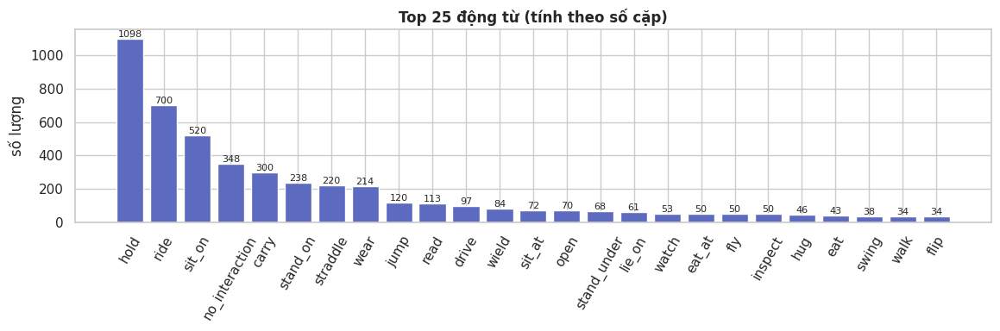

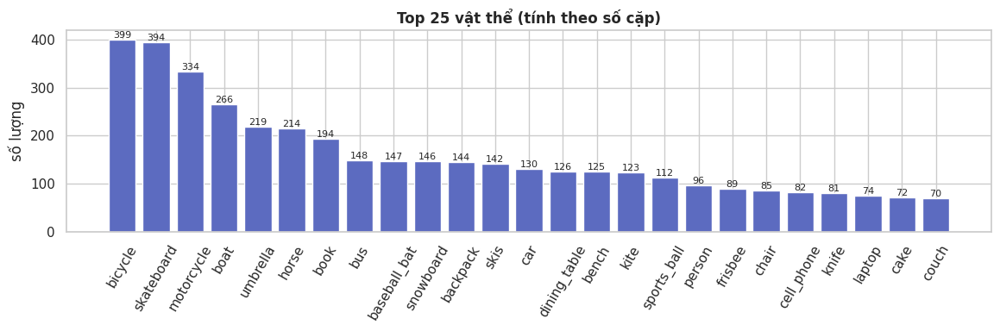

In [ ]:
print('Số ảnh                 :', len(df))
print('Số cặp HOI trung bình/ảnh:', round(df['captions'].str.len().mean(), 2))
print('Số ảnh CHỈ có no_interaction:', df['captions'].apply(lambda c: all(v == 'no_interaction' for _, v in c)).sum())

tat_ca_cap = df.explode('captions')['captions'].dropna()
dong_tu = tat_ca_cap.apply(lambda c: c[1])
vat = tat_ca_cap.apply(lambda c: c[0])
ve_cot(dong_tu[dong_tu.isin(dong_tu.value_counts().head(25).index)], 'Top 25 động từ (tính theo số cặp)')
ve_cot(vat[vat.isin(vat.value_counts().head(25).index)], 'Top 25 vật thể (tính theo số cặp)')

        width   height
min   122.000   89.000
mean  592.402  495.718
max   640.000  640.000


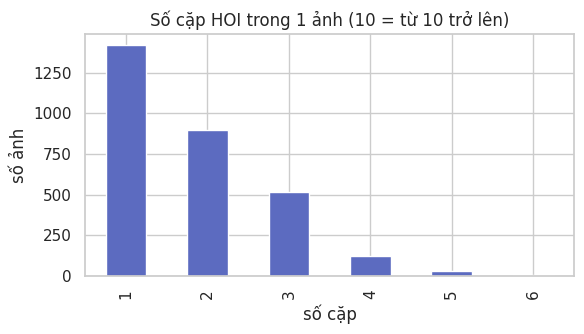

In [ ]:
print(df[['width', 'height']].describe().loc[['min', 'mean', 'max']])
fig, ax = plt.subplots(figsize=(6, 3.5))
df['captions'].str.len().clip(upper=10).value_counts().sort_index().plot.bar(ax=ax, color='#5C6BC0')
ax.set_title('Số cặp HOI trong 1 ảnh (10 = từ 10 trở lên)'); ax.set_xlabel('số cặp'); ax.set_ylabel('số ảnh')
plt.tight_layout(); plt.show()

**Xem ảnh mẫu:** 12 ảnh ngẫu nhiên. Khung xanh là người, khung cam là vật, tiêu đề là cặp (vật, động từ) được vẽ.

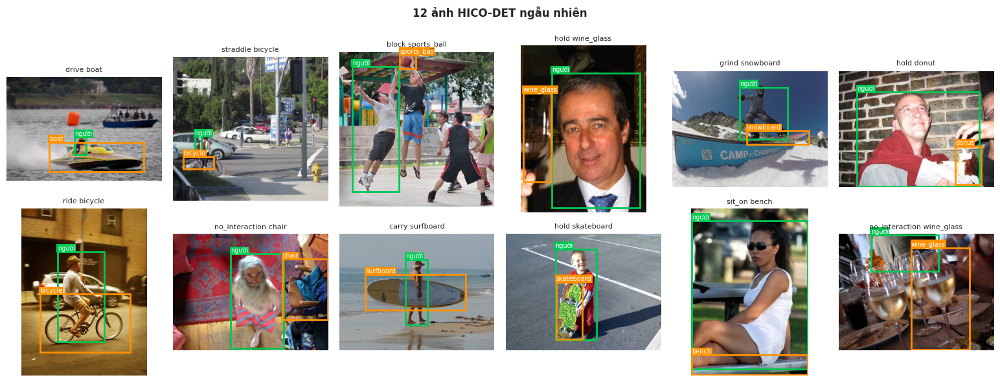

In [ ]:
items = []
for r in df[df['pairs'].str.len() > 0].sample(12, random_state=42).itertuples():
    p = r.pairs[0]
    items.append(item_cap(r.idx, p, f"{p['verb']} {p['object']}"))
show_grid(items, '12 ảnh HICO-DET ngẫu nhiên', ncols=6)

📝 **Nhận xét của bạn:**

📌 **Kết luận phần 1**
- Mỗi ảnh có nhiều cặp HOI, và 1 người thường có nhiều cặp (ví dụ vừa `ride` vừa `sit_on` vừa `straddle` xe máy).
- Có nhiều cặp `no_interaction` (có vật nhưng không tương tác).

## Phần 2: Map sang 6 nhãn đích

**Cách làm (2 bước):**
1. Map **từng cặp** (vật, động từ) sang 1 nhãn đích theo quy tắc trong hàm `map_cap` bên dưới
2. 1 ảnh có nhiều cặp, nên chọn **1 nhãn cho cả ảnh** bằng priority rule: `take_on_phone > work_on_computer > eat/drink > ride > hold > unknown`

In [ ]:
PHONE_VERBS    = {'talk_on', 'text_on', 'hold'}                 # + vật là cell_phone
COMPUTER_RULES = {'laptop': {'type_on', 'open', 'read', 'carry', 'hold'},
                  'keyboard': {'type_on', 'open', 'read', 'carry', 'hold'},
                  'mouse': {'control', 'hold'}}
EAT_DRINK_VERBS = {'eat', 'eat_at', 'drink_with', 'sip', 'pour'}
RIDE_VERBS      = {'ride', 'drive', 'row', 'sail', 'straddle', 'race'}
HOLD_VERBS_HICO = {'hold', 'carry', 'wield', 'pick_up'}

def map_cap(obj, verb):
    """Map 1 cặp (vật, động từ) → nhãn đích."""
    if obj == 'cell_phone' and verb in PHONE_VERBS:
        return 'take_on_phone'
    if verb in COMPUTER_RULES.get(obj, set()):
        return 'work_on_computer'
    if verb in EAT_DRINK_VERBS:
        return 'eat/drink'
    if verb in RIDE_VERBS:
        return 'ride'
    if verb in HOLD_VERBS_HICO:
        return 'hold'
    return 'unknown'

# Áp lên cả 600 loại HOI: xem mỗi nhãn đích gom bao nhiêu loại cặp
hoi_list['target_label'] = [map_cap(o, v) for o, v in zip(hoi_list['nname'], hoi_list['vname'])]
display(bang_dem(hoi_list['target_label'], 'nhãn đích (tính trên 600 loại HOI)'))
for cls in TARGET_CLASSES[:-1]:
    sub = hoi_list[hoi_list['target_label'] == cls]
    print(f'\n{cls} ({len(sub)} loại):', ', '.join(f'{v} {o}' for o, v in zip(sub.nname, sub.vname))[:600])

,nhãn đích (tính trên 600 loại HOI),số lượng,tỷ lệ %
0,unknown,443,73.8
1,hold,97,16.2
2,ride,30,5.0
3,eat/drink,18,3.0
4,work_on_computer,9,1.5
5,take_on_phone,3,0.5



hold (97 loại): carry bicycle, hold bicycle, hold bird, carry bottle, hold bottle, hold cat, carry chair, hold chair, carry couch, hold cow, carry dog, hold dog, hold horse, hold motorcycle, carry person, hold person, carry potted_plant, hold potted_plant, carry sheep, hold sheep, hold apple, carry backpack, hold backpack, carry banana, hold banana, carry baseball_bat, hold baseball_bat, wield baseball_bat, hold baseball_glove, carry book, hold book, hold bowl, hold broccoli, carry cake, hold cake, pick_up cake, carry carrot, hold carrot, carry cell_phone, hold clock, carry cup, hold cup, carry donut, hold do

ride (30 loại): ride airplane, ride bicycle, straddle bicycle, drive boat, ride boat, row boat, sail boat, drive bus, ride bus, drive car, ride car, ride cow, straddle dog, race horse, ride horse, straddle horse, race motorcycle, ride motorcycle, straddle motorcycle, ride sheep, drive train, ride train, ride elephant, ride giraffe, ride skateboard, ride skis, ride snowboard, rid

,nhãn đích,số lượng,tỷ lệ %
0,unknown,1125,37.5
1,hold,916,30.5
2,ride,742,24.7
3,eat/drink,118,3.9
4,work_on_computer,67,2.2
5,take_on_phone,32,1.1


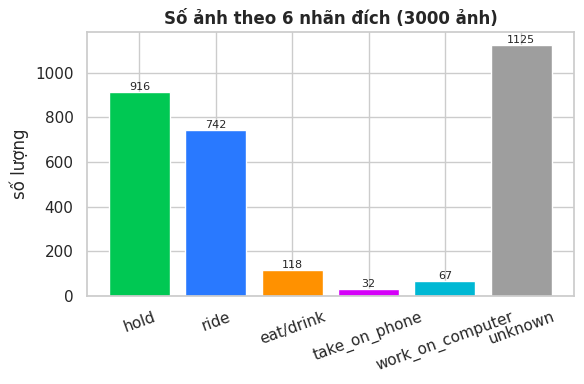

In [ ]:
def map_anh(pairs):
    """Chọn 1 nhãn cho cả ảnh + trả về cặp 'thắng' (để vẽ bbox)."""
    if not pairs:
        return 'unknown', None
    tot_nhat = min(pairs, key=lambda p: PRIORITY.index(map_cap(p['object'], p['verb'])))
    return map_cap(tot_nhat['object'], tot_nhat['verb']), tot_nhat

ket_qua = [map_anh(p) for p in df['pairs']]
df['target_label'] = [nhan for nhan, cap in ket_qua]
df['chosen'] = [cap for nhan, cap in ket_qua]
df['original_label'] = df['chosen'].apply(lambda p: f"{p['verb']} {p['object']}" if p else '(không có cặp)')
display(bang_dem(df['target_label'], 'nhãn đích'))
ve_cot(df['target_label'], f'Số ảnh theo 6 nhãn đích ({len(df)} ảnh)', theo_6_lop=True, xoay=20)

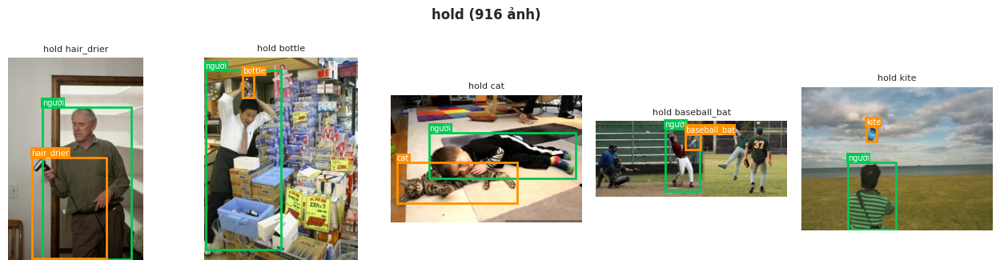

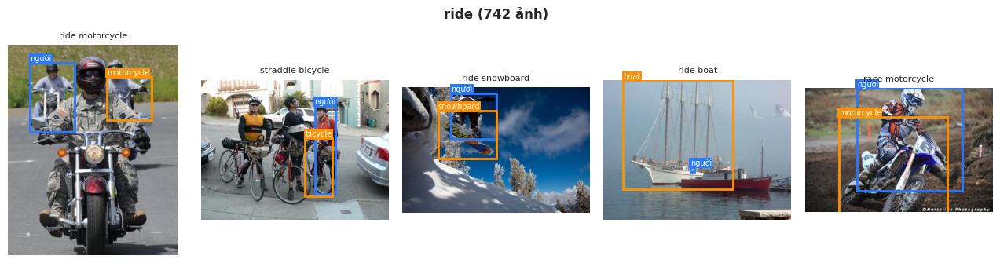

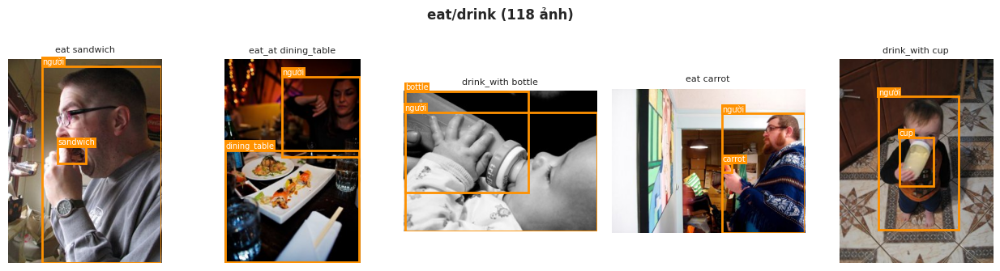

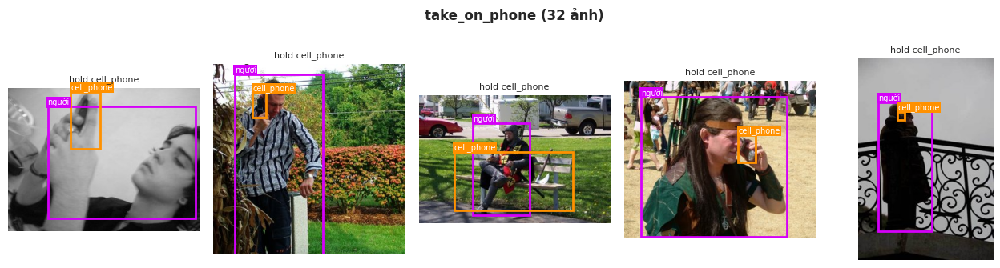

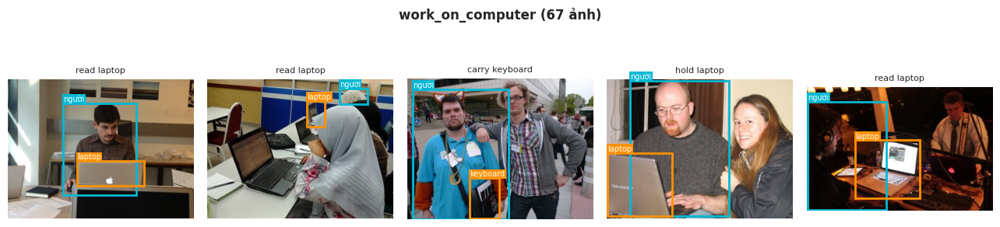

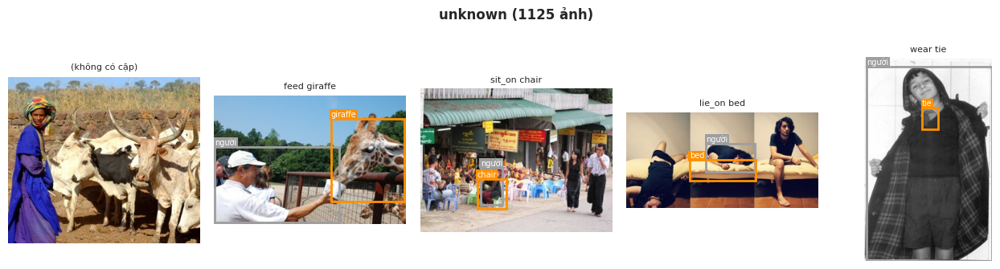

In [ ]:
for cls in TARGET_CLASSES:
    sub = df[df['target_label'] == cls]
    if len(sub) == 0:
        print(f'ℹ️ {cls}: 0 ảnh trong {len(df)} ảnh đã tải'); continue
    rows = sub.sample(min(5, len(sub)), random_state=42)
    show_grid([item_cap(r.idx, r.chosen, r.original_label, CLASS_COLORS[cls]) for r in rows.itertuples()],
              f'{cls} ({len(sub)} ảnh)', ncols=5)

In [ ]:
df['hold_object'] = df.apply(lambda r: r.chosen['object'] if r.target_label == 'hold' else '', axis=1)
df['hold_verb'] = df.apply(lambda r: r.chosen['verb'] if r.target_label == 'hold' else '', axis=1)
hop = lambda b: ','.join(str(int(v)) for v in b) if b else ''

df_labels = pd.DataFrame({
    'dataset': 'hico_det',
    'image': 'hico_det_train_idx_' + df['idx'].astype(str),    # vị trí ảnh trong split train của HF
    'person_bbox': df['chosen'].apply(lambda p: hop(p['hbox']) if p else ''),
    'object_bbox': df['chosen'].apply(lambda p: hop(p['obox']) if p else ''),
    'original_label': df['original_label'],
    'target_label': df['target_label'],
    'hold_object': df['hold_object'],
    'hold_verb': df['hold_verb'],
})
print('Đã tạo df_labels:', df_labels.shape, '(mỗi dòng = 1 ảnh, bbox là của cặp được chọn)')

Đã tạo df_labels: (3000, 8) (mỗi dòng = 1 ảnh, bbox là của cặp được chọn)


📌 **Kết luận phần 2**
- Trên 600 loại HOI: `unknown` 443 loại (74%), `hold` 97, `ride` 30, `eat/drink` 18, `work_on_computer` 9, `take_on_phone` chỉ **3** loại, nên rất hiếm.
- Nhãn đang gắn cho **cả ảnh**, bbox trong file là của **cặp thắng** theo priority rule.

## Phần 3: Những chỗ map đáng nghi

Mỗi mục có *lý do*, *số ảnh bị ảnh hưởng* (ảnh có cặp thắng rơi vào trường hợp đó), và *6 ảnh*. Xem xong, trả lời **Giữ / Bỏ / Đổi lớp?**

🔎 Chỉ CẦM điện thoại → take_on_phone  |  5 ảnh  (trong 3000 ảnh đã tải)
   Lý do nghi ngờ: Cầm điện thoại chưa chắc đang nghe/nhắn tin.


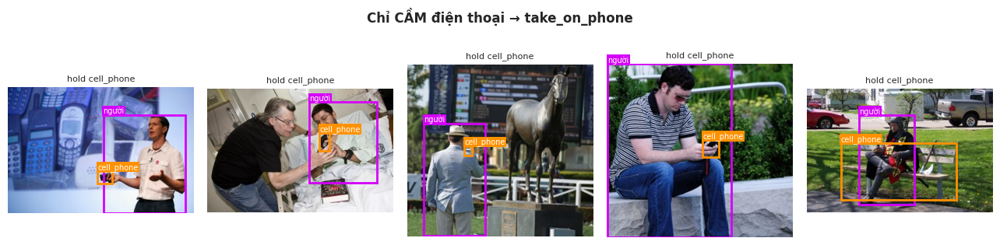

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Chỉ cầm/mang/mở laptop → work_on_computer  |  38 ảnh  (trong 3000 ảnh đã tải)
   Lý do nghi ngờ: Cầm hoặc mở laptop chưa chắc đang làm việc với máy tính.


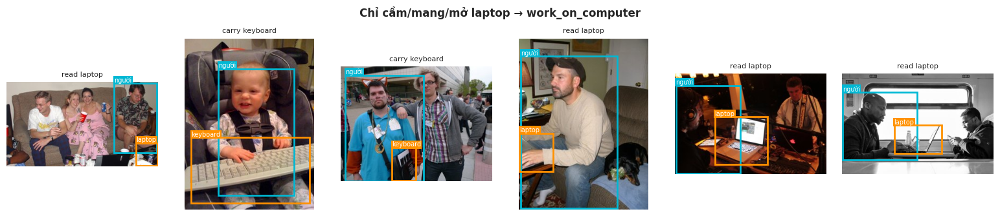

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Rót (pour) → eat/drink  |  1 ảnh  (trong 3000 ảnh đã tải)
   Lý do nghi ngờ: Rót đồ uống chứ không phải đang ăn/uống.


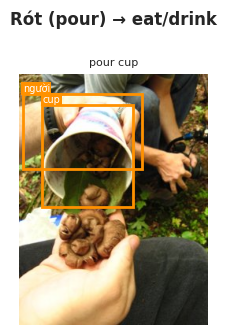

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Ngồi ở bàn ăn (eat_at) → eat/drink  |  49 ảnh  (trong 3000 ảnh đã tải)
   Lý do nghi ngờ: Ngồi cạnh bàn ăn chưa chắc đang ăn.


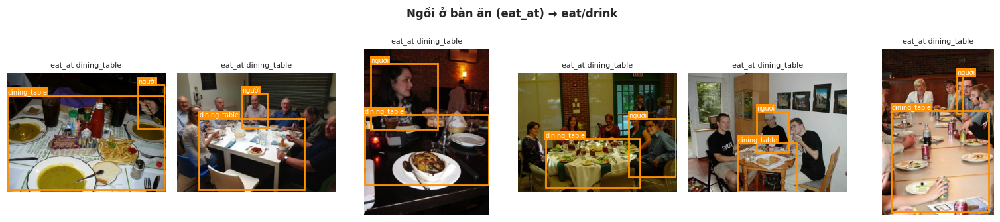

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 straddle / race / sail / row → ride  |  84 ảnh  (trong 3000 ảnh đã tải)
   Lý do nghi ngờ: Đứng dạng chân qua xe, đua, chèo/lái thuyền: khác với "cưỡi/lái".


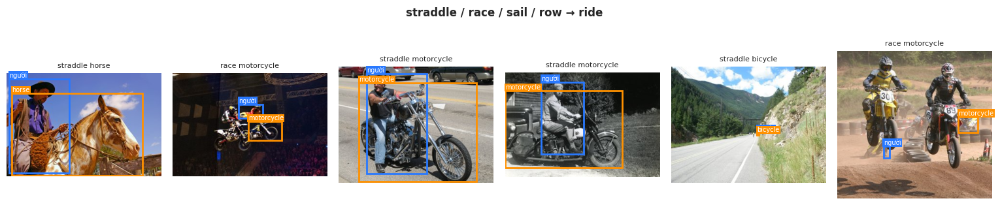

   ❓ Giữ / Bỏ / Đổi lớp?


In [ ]:
def co_dong_tu(r, verbs):
    return any(v in verbs for _, v in r.captions)

NGHI_NGO = [
    {'ten': 'Chỉ CẦM điện thoại → take_on_phone',
     'dieu_kien': lambda r: r.chosen and r.chosen['object'] == 'cell_phone' and r.chosen['verb'] == 'hold'
                            and not co_dong_tu(r, {'talk_on', 'text_on'}),
     'ly_do': 'Cầm điện thoại chưa chắc đang nghe/nhắn tin.'},
    {'ten': 'Chỉ cầm/mang/mở laptop → work_on_computer',
     'dieu_kien': lambda r: r.target_label == 'work_on_computer' and not co_dong_tu(r, {'type_on', 'control'}),
     'ly_do': 'Cầm hoặc mở laptop chưa chắc đang làm việc với máy tính.'},
    {'ten': 'Rót (pour) → eat/drink',
     'dieu_kien': lambda r: r.target_label == 'eat/drink' and r.chosen['verb'] == 'pour',
     'ly_do': 'Rót đồ uống chứ không phải đang ăn/uống.'},
    {'ten': 'Ngồi ở bàn ăn (eat_at) → eat/drink',
     'dieu_kien': lambda r: r.target_label == 'eat/drink' and r.chosen['verb'] == 'eat_at',
     'ly_do': 'Ngồi cạnh bàn ăn chưa chắc đang ăn.'},
    {'ten': 'straddle / race / sail / row → ride',
     'dieu_kien': lambda r: r.target_label == 'ride' and r.chosen['verb'] in {'straddle', 'race', 'sail', 'row'},
     'ly_do': 'Đứng dạng chân qua xe, đua, chèo/lái thuyền: khác với "cưỡi/lái".'},
]

for ng in NGHI_NGO:
    sub = df[df.apply(ng['dieu_kien'], axis=1).astype(bool)]
    print('=' * 100)
    print(f"🔎 {ng['ten']}  |  {len(sub)} ảnh  (trong {len(df)} ảnh đã tải)")
    print(f"   Lý do nghi ngờ: {ng['ly_do']}")
    rows = sub.sample(min(6, len(sub)), random_state=1)
    show_grid([item_cap(r.idx, r.chosen, r.original_label, CLASS_COLORS[r.target_label]) for r in rows.itertuples()], ng['ten'])
    print('   ❓ Giữ / Bỏ / Đổi lớp?')

### 3.2 1 ảnh có cặp thuộc nhiều nhãn đích khác nhau
Priority rule chỉ giữ **1 nhãn** cho cả ảnh, nên các nhãn còn lại bị **mất**. Ví dụ ảnh có người đi xe đạp (`ride`) và người cầm ô (`hold`) thì chỉ còn `ride`.

236 / 3000 ảnh (7.9%) có ≥2 nhãn đích (không tính unknown)


,tổ hợp nhãn,số lượng,tỷ lệ %
0,hold + ride,159,67.4
1,eat/drink + hold,62,26.3
2,hold + take_on_phone,15,6.4


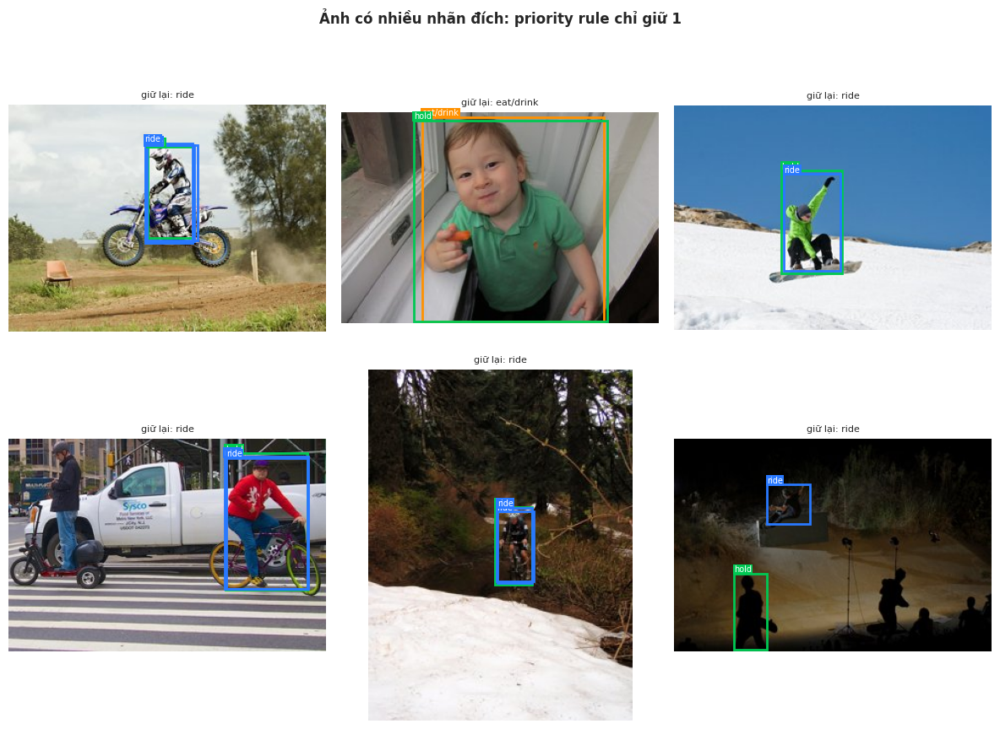

In [ ]:
df['cac_nhan'] = df['pairs'].apply(lambda ps: sorted({map_cap(p['object'], p['verb']) for p in ps} - {'unknown'}))
nhieu = df[df['cac_nhan'].str.len() >= 2]
print(f'{len(nhieu)} / {len(df)} ảnh ({len(nhieu) / len(df) * 100:.1f}%) có ≥2 nhãn đích (không tính unknown)')
display(bang_dem(nhieu['cac_nhan'].apply(' + '.join), 'tổ hợp nhãn').head(10))

items = []
for r in nhieu.sample(min(6, len(nhieu)), random_state=0).itertuples():
    s = thumbs[r.idx][1]
    boxes = [(*[v * s for v in p['hbox']], CLASS_COLORS[map_cap(p['object'], p['verb'])], map_cap(p['object'], p['verb']))
             for p in r.pairs if map_cap(p['object'], p['verb']) != 'unknown']
    items.append({'img': anh_nho(r.idx), 'title': f"giữ lại: {r.target_label}", 'boxes': boxes})
show_grid(items, 'Ảnh có nhiều nhãn đích: priority rule chỉ giữ 1', ncols=3, size=4)

### 3.3 Nhóm `unknown` gồm những gì?

In [ ]:
unk = df[df['target_label'] == 'unknown']
chi_no_inter = unk['captions'].apply(lambda c: all(v == 'no_interaction' for _, v in c))
print(f'{len(unk)} ảnh unknown, trong đó {chi_no_inter.sum()} ảnh CHỈ có no_interaction')
dt_unk = unk.explode('captions')['captions'].dropna().apply(lambda c: c[1])
bang_dem(dt_unk, 'động từ trong ảnh unknown').head(15)

1125 ảnh unknown, trong đó 333 ảnh CHỈ có no_interaction


,động từ trong ảnh unknown,số lượng,tỷ lệ %
0,no_interaction,337,26.2
1,sit_on,243,18.9
2,wear,72,5.6
3,lie_on,55,4.3
4,watch,48,3.7
5,stand_on,37,2.9
6,jump,31,2.4
7,fly,30,2.3
8,feed,29,2.3
9,sit_at,28,2.2


📌 **Kết luận phần 3**: các quyết định cần chốt:
- `hold cell_phone` / `hold laptop`: có tính là đang dùng không?
- `pour`, `eat_at`, `straddle`, `race`: giữ hay loại?
- Ảnh nhiều nhãn: nên chuyển sang gán nhãn **theo từng người (bbox người)** thay vì cả ảnh.
- `unknown` chứa cả `no_interaction` lẫn hàng trăm tương tác khác (`sit_on`, `stand_on`, `look_at`…), cần định nghĩa rõ.

## Phần 4: Lớp `hold` quá rộng: dẫn chứng và đề xuất

### 4.1 Dẫn chứng

In [ ]:
hold_hoi = hoi_list[hoi_list['target_label'] == 'hold']
print(f'Trên danh mục: {len(hold_hoi)} / 600 loại HOI được map vào hold, gồm {hold_hoi.nname.nunique()} loại vật khác nhau')
print('Các vật:', ', '.join(sorted(hold_hoi.nname.unique())))

Trên danh mục: 97 / 600 loại HOI được map vào hold, gồm 59 loại vật khác nhau
Các vật: apple, backpack, banana, baseball_bat, baseball_glove, bicycle, bird, book, bottle, bowl, broccoli, cake, carrot, cat, cell_phone, chair, clock, couch, cow, cup, dog, donut, elephant, fork, frisbee, hair_drier, handbag, horse, hot_dog, kite, knife, motorcycle, orange, oven, person, pizza, potted_plant, refrigerator, remote, sandwich, scissors, sheep, skateboard, skis, snowboard, spoon, sports_ball, stop_sign, suitcase, surfboard, teddy_bear, tennis_racket, tie, toaster, toothbrush, umbrella, vase, wine_glass, zebra


In [ ]:
hold_df = df_labels[df_labels['target_label'] == 'hold']
if len(hold_df) == 0:
    print('Lớp hold không có mẫu nào trong bộ này.')
else:
    comp = bang_dem(hold_df['hold_object'].astype(str) + '  |  ' + hold_df['hold_verb'].astype(str),
                    'vật | hành động')
    print(f'Lớp hold có {len(hold_df)} mẫu, gồm {len(comp)} kiểu (vật | hành động) khác nhau')
    top5 = comp['số lượng'].head(5).sum() / len(hold_df) * 100
    print(f'Top-5 kiểu chiếm {top5:.1f}% lớp hold '
          '(càng thấp = càng phân tán = càng khó học)')
    counts = df_labels['target_label'].value_counts()
    nho_nhat = counts[counts > 0].min()
    print(f'hold gấp {counts["hold"] / nho_nhat:.1f} lần lớp nhỏ nhất ({counts.idxmin()}: {nho_nhat})')
    display(comp.head(20))

Lớp hold có 916 mẫu, gồm 85 kiểu (vật | hành động) khác nhau
Top-5 kiểu chiếm 30.1% lớp hold (càng thấp = càng phân tán = càng khó học)
hold gấp 28.6 lần lớp nhỏ nhất (take_on_phone: 32)


,vật | hành động,số lượng,tỷ lệ %
0,book | hold,67,7.3
1,backpack | carry,63,6.9
2,baseball_bat | hold,55,6.0
3,umbrella | carry,51,5.6
4,frisbee | hold,40,4.4
5,umbrella | hold,37,4.0
6,person | hold,34,3.7
7,knife | hold,29,3.2
8,wine_glass | hold,25,2.7
9,bottle | hold,22,2.4


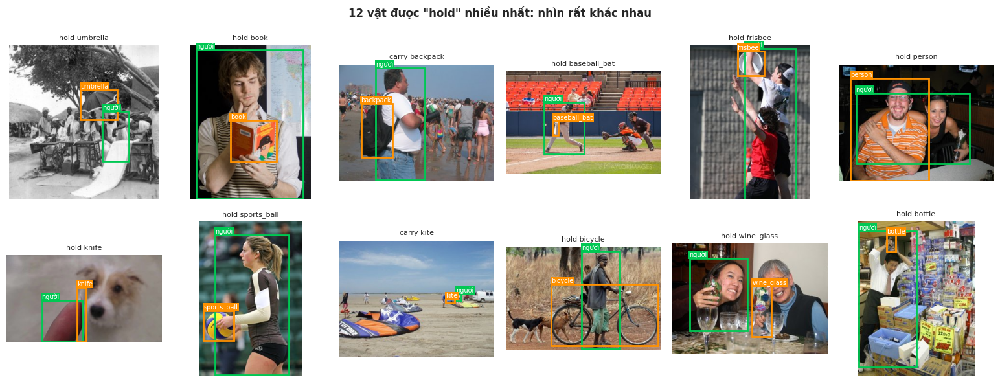

In [ ]:
hold_df = df[df['target_label'] == 'hold']
items = []
for obj in hold_df['hold_object'].value_counts().head(12).index:
    r = hold_df[hold_df['hold_object'] == obj].sample(1, random_state=3).iloc[0]
    items.append(item_cap(r.idx, r.chosen, r.original_label, CLASS_COLORS['hold']))
show_grid(items, '12 vật được "hold" nhiều nhất: nhìn rất khác nhau', ncols=6)

### 4.2 Ba phương án giới hạn `hold`

| Phương án | Ý tưởng | Đổi nhãn? |
|---|---|---|
| **A. Theo vật thể** | Chỉ giữ `hold` khi vật là **đồ nhỏ cầm tay** (danh sách `HOLD_OBJECTS` bên dưới). Nhạc cụ, ván trượt, vợt, gậy, diều… chuyển sang `unknown` | Có |
| **B. Theo động từ** | Chỉ giữ `hold` khi hành động đúng là **cầm/mang** (`hold`, `carry`). Các hành động "chơi", "chụp", "vung"… chuyển sang `unknown` | Có |
| **C. Cắt số lượng** | Giữ nguyên định nghĩa, chỉ **bớt mẫu `hold`** khi training (tối đa `k` lần lớp nhỏ nhất) | Không, chỉ đổi cách lấy mẫu |

👉 **Khuyến nghị mặc định: A + B**, tức `hold` = *cầm hoặc mang một vật nhỏ bằng tay*. Định nghĩa hẹp và rõ thì model dễ học hơn. **C** để dành cho lúc training (dùng sampler), không dùng để sửa nhãn.

Bạn đổi phương án bằng biến `HOLD_POLICY` ở cell dưới: `None`, `'A'`, `'B'`, `'A+B'`.

In [ ]:
HOLD_POLICY = 'A+B'   # 👈 đổi ở đây: None | 'A' | 'B' | 'A+B'

# Đồ vật nhỏ cầm tay (tên theo kiểu COCO, dùng dấu gạch dưới)
HOLD_OBJECTS = {
    'cup', 'bottle', 'wine_glass', 'bowl', 'umbrella', 'handbag', 'backpack', 'suitcase', 'tie',
    'book', 'knife', 'fork', 'spoon', 'scissors', 'remote', 'toothbrush', 'hair_drier',
    'teddy_bear', 'vase', 'camera', 'clock', 'banana', 'apple', 'orange', 'sandwich',
    'hot_dog', 'pizza', 'donut', 'cake', 'carrot', 'broccoli',
}
HOLD_VERBS = {'hold', 'carry'}


def gioi_han_hold(row, policy=HOLD_POLICY):
    """Trả về nhãn mới sau khi áp phương án giới hạn hold cho 1 dòng."""
    lbl = row['target_label']
    if lbl != 'hold' or policy is None:
        return lbl
    obj = str(row.get('hold_object', '')).replace(' ', '_')
    verb = str(row.get('hold_verb', ''))
    if 'A' in policy and obj not in HOLD_OBJECTS:
        return 'unknown'
    if 'B' in policy and verb not in HOLD_VERBS:
        return 'unknown'
    return lbl


def so_sanh_phuong_an(df):
    """Bảng số mẫu 6 lớp: trước và sau từng phương án A, B, A+B, và C (k=3)."""
    out = pd.DataFrame(index=TARGET_CLASSES)
    out['hiện tại'] = df['target_label'].value_counts().reindex(TARGET_CLASSES, fill_value=0)
    for p in ['A', 'B', 'A+B']:
        out[p] = df.apply(lambda r: gioi_han_hold(r, p), axis=1).value_counts().reindex(TARGET_CLASSES, fill_value=0)
    nho_nhat = out['hiện tại'][out['hiện tại'] > 0].min()
    out['C (k=3)'] = out['hiện tại']
    out.loc['hold', 'C (k=3)'] = min(out.loc['hold', 'hiện tại'], 3 * nho_nhat)
    return out

,hiện tại,A,B,A+B,C (k=3)
hold,916,529,906,523,96
ride,742,742,742,742,742
eat/drink,118,118,118,118,118
take_on_phone,32,32,32,32,32
work_on_computer,67,67,67,67,67
unknown,1125,1512,1135,1518,1125


Phương án A+B: 393 ảnh bị đẩy ra khỏi hold. Hay bị loại nhất:


,cặp,số lượng,tỷ lệ %
0,hold baseball_bat,55,14.0
1,hold frisbee,40,10.2
2,hold person,34,8.7
3,hold bicycle,22,5.6
4,carry sports_ball,18,4.6
5,hold baseball_glove,16,4.1
6,hold kite,15,3.8
7,carry surfboard,13,3.3
8,carry tennis_racket,13,3.3
9,carry kite,12,3.1


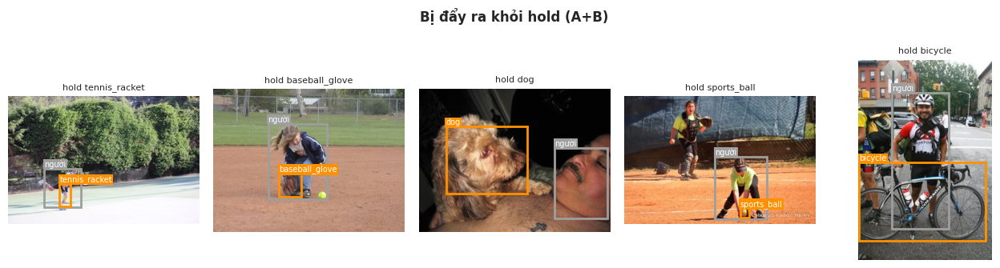

In [ ]:
display(so_sanh_phuong_an(df_labels))
df_labels['target_label_hold_limited'] = df_labels.apply(gioi_han_hold, axis=1)

bi_day = df[(df_labels['target_label'] == 'hold') & (df_labels['target_label_hold_limited'] != 'hold')]
print(f'Phương án {HOLD_POLICY}: {len(bi_day)} ảnh bị đẩy ra khỏi hold. Hay bị loại nhất:')
display(bang_dem(bi_day['original_label'], 'cặp').head(10))
show_grid([item_cap(r.idx, r.chosen, r.original_label, '#9E9E9E') for r in bi_day.sample(min(5, len(bi_day)), random_state=0).itertuples()],
          f'Bị đẩy ra khỏi hold ({HOLD_POLICY})', ncols=5)

In [ ]:
df_labels.to_csv('labels_6class_hico_det.csv', index=False)
print('💾 Đã lưu', os.path.abspath('labels_6class_hico_det.csv'), df_labels.shape)

💾 Đã lưu /content/labels_6class_hico_det.csv (3000, 9)


📌 **Kết luận phần 4**
- Trên danh mục, **97/600 loại HOI** với **59 loại vật** được map vào `hold`: không chỉ đồ cầm tay mà cả **người** (bế người), **động vật** (chó, mèo, ngựa, bò…), **đồ nội thất** (ghế, sofa), **xe đạp**, thậm chí **tủ lạnh**.
- 4 động từ `hold`, `carry`, `wield`, `pick_up` có tư thế rất khác nhau.
- **A** loại dụng cụ thể thao và vật lớn; **B** loại `wield`/`pick_up`. **A+B** giữ lại `hold` = *cầm/mang vật nhỏ*.
- Nhớ tăng `N_SAMPLES` (ví dụ 10.000) để số liệu chắc chắn hơn trước khi chốt.